# Treatment effects: `CausalSpec`, `aipw` and `effect_model`

An intervention effect is a contrast between the outcomes the same units would
have under two assigned treatments. A fitted association between treatment and
outcome estimates it only under the assumptions listed here. Before
estimation, name the treatment contrast, outcome, target population, unit,
time zero, follow-up, and baseline adjustment set. `CausalSpec` stores those
choices and four assumptions:

- consistency: a unit's observed outcome equals its potential outcome under
  the treatment it received, so the treatment is well defined;
- conditional exchangeability: given the adjustment covariates, the treatment
  received is independent of the potential outcomes (no unmeasured
  confounding);
- positivity: every covariate value in the target population has a non-zero
  probability of receiving each treatment;
- no interference: one unit's treatment does not change another unit's
  outcome.

The data cannot verify all four.

The main estimator, `aipw`, is augmented inverse-probability weighting
(AIPW). It estimates the average treatment effect (ATE) over the target
population or the average treatment effect on the treated (ATT), for a binary
treatment, continuous mean differences or binary risk differences (declared
with `outcome_type="binary"`), and numeric baseline covariates. With ordinary
folds the rows are treated as independent and identically distributed (IID),
and the standard error comes from the influence function: each row's score
$\psi_i$ (defined in the AIPW score section) is its contribution to the
estimate, and the variance of the estimate is the sample variance of the
$\psi_i$ divided by $n$. A grouped fold scheme keeps each sampling unit
together, computes the variance from the per-cluster sums of $\psi_i$ with a
small-sample correction for the number of clusters $G$, and reports a
$t_{G-1}$ interval. Ordered (time-series) dependence requires a separately
specified variance model.

## The cross-fitted AIPW score

For treatment $A$, outcome $Y$, propensity $e(X)=P(A=1\mid X)$, and outcome
regressions $\mu_a(X)=E(Y\mid A=a,X)$, the ATE score is

$$\psi_i = \mu_1(X_i)-\mu_0(X_i) + \frac{A_i(Y_i-\mu_1(X_i))}{e(X_i)} - \frac{(1-A_i)(Y_i-\mu_0(X_i))}{1-e(X_i)}.$$

The propensity and outcome regressions are nuisance models: they are needed to
compute the score but are not the target. `aipw` cross-fits them: the rows are
split into folds, and the nuisance predictions for the rows of one fold come
from models fitted on the other folds, so every prediction for observation $i$
is made without it. The estimate is the mean of the returned $\psi_i$. Inner
cross-validation chooses nuisance stopping iterations using outer-training
rows only.

The score is orthogonal: small errors in $e$ and $\mu_a$ change its mean only
through the product of the two errors. Cross-fitting removes the bias of
evaluating a model on its own training rows. Together they make the estimate
less sensitive to nuisance estimation error; they do not supply conditional
exchangeability or positivity {cite}`chernozhukov2018double`. Setting
`repeats>1` averages nuisance predictions from independently drawn
cross-fitting partitions. The reported interval remains conditional on that
procedure and does not add a separate variance component for partition
randomness.

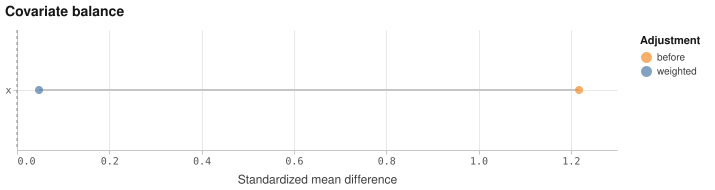

In [1]:
import numpy as np
import polars as pl
import mboostrs as mb

rng = np.random.default_rng(4)
n = 1200
x = rng.normal(size=n)
propensity = 1 / (1 + np.exp(-1.5 * x))
treated = (rng.random(n) < propensity).astype(float)
outcome = 2 * treated + 2 * x + rng.normal(size=n)
placebo = 0.8 * x + rng.normal(size=n)  # generated before treatment
data = pl.DataFrame({"x": x, "treated": treated, "outcome": outcome, "placebo": placebo})

design = mb.CausalSpec(
    treatment="treated", outcome="outcome", covariates=("x",),
    estimand="ate", target_population="the study sample", unit="person",
    time_zero="treatment assignment", follow_up="one year",
    adjustment_rationale="x causes treatment uptake and the outcome",
)
result = mb.aipw(data, design, folds=5, mstop=150, tune=False)
result.describe()
mb.plot.plot_causal_overlap(result)
mb.plot.plot_causal_balance(result)


## Estimate reconstruction and overlap diagnostics

The simulation sets the treatment effect to 2. Confounding makes the raw
treated-minus-control mean difference too large (4.21) because `x` raises
both treatment probability and outcome. The mean of the row scores is the
AIPW estimate (2.13), which recovers the adjusted estimand under the known
simulation design.

In [2]:
rows = result.to_frame(output="polars")
naive = data.filter(pl.col("treated") == 1)["outcome"].mean() - data.filter(pl.col("treated") == 0)["outcome"].mean()
pl.DataFrame({
    "quantity": ["naive mean difference", "cross-fitted AIPW", "score mean"],
    "estimate": [naive, result.estimate, rows["score"].mean()],
})


quantity,estimate
str,f64
"""naive mean difference""",4.20861
"""cross-fitted AIPW""",2.133564
"""score mean""",2.133564


## Conditional effects: `effect_model`

`effect_model` estimates the conditional average treatment effect
$\tau(x) = E(Y^{(1)} - Y^{(0)} \mid X = x)$ over the covariates. By default
the fitted form is additive, so each covariate's contribution to the effect
can be read as a curve; `terms="joint"` fits one tree over all the
covariates instead, which is what an effect that turns on two covariates at
once needs. It uses the R-learner {cite}`nie2021quasi`, which regresses outcome residuals on treatment residuals: with the cross-fitted
outcome mean $m(X) = E(Y \mid X)$ and propensity $e(X)$, $\tau$ minimizes
the R-loss

$$\sum_i \bigl(Y_i - m(X_i) - (A_i - e(X_i))\,\tau(X_i)\bigr)^2
= \sum_i (A_i - e(X_i))^2 \bigl(Z_i - \tau(X_i)\bigr)^2,
\qquad Z_i = \frac{Y_i - m(X_i)}{A_i - e(X_i)}.$$

The right-hand form is a weighted least-squares problem for the
pseudo-outcome $Z$ with weights $(A - e)^2$, which is fitted like any other
weighted Gaussian regression. Regressing $Z$ on the covariates gives the effect at each covariate value. The two residuals $Y - m$ and $A - e$ remove the
confounders' effect on the outcome before $\tau$ is fitted, so a covariate
that only confounds does not enter $\tau$ when the nuisances are accurate. A
row whose treatment the covariates nearly determine has a large $Z$ and a
proportionally small weight.

Under `terms="auto"` three candidate sets of terms are fitted:

- `"smooth"`: a penalized smooth for each covariate (a linear term for a
  covariate with fewer than ten distinct values), with the smoothing chosen by
  restricted maximum likelihood (REML);
- `"stumps"`: a boosted model with a one-split tree for each covariate, for
  effects that jump at a threshold;
- `"joint"`: one boosted depth-3 tree that may split on any covariate.

Each candidate is scored by its R-loss on held-out folds. Only candidates
that beat a constant effect by more than one standard error are eligible, and
the one with the lowest loss is kept, with two exceptions: the joint tree must
be at least 5 percent lower than the best additive candidate, and a choice
that beats `"smooth"` by no more than one standard error of the loss
difference is replaced by `"smooth"`. Losses that close do not separate the
candidates, and the additive form reads as one curve per modifier.

The candidates are not mixed in one model, because a tree reduces the
residual more per step than a one-degree-of-freedom smooth and would be
selected even for a smooth effect.

The joint tree is what an effect of the form $1 + 1.5\,\mathbb{1}(x_1 x_2 >
0)$ requires: each of its two covariates has a flat effect on its own, so
every additive candidate fits the same flat curve. Its splits are chosen by
squared error rather than by the conditional-inference test that tree
learners use by default (a test of association between each covariate and the
current residual), because a covariate whose effect needs another covariate to
appear has a marginal association near zero and would never be offered as the
first split. Pass `terms="joint"` to fit it alone, or `modifiers=` to restrict
the modifiers it may split on.

In the simulation for this section the effect rises linearly with `x`, from 1
at `x = -1` to 3 at `x = 1`, and a second covariate `z` confounds without
changing the effect.

In [3]:
rng = np.random.default_rng(7)
n = 2000
x, z = rng.uniform(-1.5, 1.5, (2, n))
treated = rng.binomial(1, 1 / (1 + np.exp(-(0.8 * x + 0.8 * z)))).astype(float)
effect = 2 + x
outcome = effect * treated + np.sin(2 * x) + z + rng.normal(0, 0.5, n)
hetero = pl.DataFrame({"x": x, "z": z, "treated": treated, "outcome": outcome})

hetero_design = mb.CausalSpec(
    treatment="treated", outcome="outcome", covariates=("x", "z"),
    time_zero="treatment assignment", follow_up="one year",
    adjustment_rationale="x and z cause both treatment uptake and the outcome",
)
fx = mb.effect_model(hetero, hetero_design, seed=1)
fx


EffectModel(terms='smooth', modifiers=['x', 'z'], ate_plugin=2.03449, n=2000)

`fx.terms` names the chosen candidate (`"smooth"` here) and `fx.cv_rloss`
holds the held-out R-loss of every candidate. For `"smooth"`, `fx.model` is a
penalized additive model of $\tau$; for `"stumps"` and `"joint"` it is a
boosted model. Its partial effects show how each covariate modifies the
effect. The estimated effect is 1.04 at `x = -1` and 3.03 at `x = 1`, against
true values of 1 and 3, and moving `z` from 0 to 1 changes it by 0.005.

In [4]:
grid = pl.DataFrame({"x": np.linspace(-1, 1, 5), "z": np.zeros(5)})
pl.DataFrame({
    "x": grid["x"],
    "true effect": 2 + grid["x"],
    "estimated effect": fx.predict(grid),
    "estimate with z = 1": fx.predict(grid.with_columns(pl.lit(1.0).alias("z"))),
})


x,true effect,estimated effect,estimate with z = 1
f64,f64,f64,f64
-1.0,1.0,1.039888,1.045188
-0.5,1.5,1.537537,1.542837
0.0,2.0,2.035186,2.040486
0.5,2.5,2.532835,2.538136
1.0,3.0,3.030485,3.035785


`nuisance=result` reuses the outcome and propensity models of an `aipw`
fit on the same rows ($m = e\,\mu_1 + (1 - e)\,\mu_0$), so one
cross-fitting run gives the average effect with its interval and the
conditional effect. `modifiers=` restricts $\tau$ to a subset of the
covariates when the design says which ones can modify the effect.

With `terms="smooth"`, `fx.predict(newdata, interval=True)` returns for each
row the estimate, a standard error and a pointwise interval. The default
interval (`interval_method="auto"`) refits the second stage on resampled rows
with the nuisance predictions held fixed, so it does not include the error of
the nuisance models; `interval_method="repeats"` and `"bootstrap"` refit the
nuisances as well. The boosted candidates `"stumps"` and `"joint"` have no
per-row interval. `fx.ate_plugin`, the mean of $\tau$ over the rows, has no
standard error; `aipw` gives the average effect with one. A fitted `joint`
model reports one `partial_effects` row for the tree rather than one row per
covariate, since no covariate's share of it is separate from the others. On
simulated designs with a smooth effect, with an effect that jumps at a
threshold, and with an effect that needs two covariates at once,
`effect_model` is compared with causal forests and other learners in
[](../cases/benchmark_causal.ipynb).

## Subgroup effects and an effect surface

The score of each row has the average treatment effect as its mean, so the
mean of the scores in a subgroup estimates the effect in that subgroup.
`AIPWResult.subgroup_effect(by)` returns, for each subgroup, the row count, this
mean, its standard error and an interval. `by` is a boolean mask over the
training rows or the name of a column of the training data, which gives one
subgroup per value. The standard error is the one `aipw` computes for the
overall estimate, with the subgroup's scores in place of all scores, so a
subgroup holding every row returns `result.estimate` and
`result.standard_error`. Choosing subgroups after looking at the data is not
reflected in the interval.

`AIPWResult.effect_surface(formula)` regresses the scores on the covariates
in `formula` with `gamboost` (the doubly robust second stage, or DR-learner).
The expected score given the covariates is the conditional effect, so
`predict` on the returned model estimates the effect as a function of the
covariates. The scores are noisy pseudo-outcomes, and intervals from the
second-stage model ignore the error of the first-stage nuisance models, so
they are too narrow.


In [5]:
x_positive = (data["x"] > 0).to_numpy()
subgroups = result.subgroup_effect(x_positive)

surface = result.effect_surface("bbs(x, df=4)", mstop=100)
grid = pl.DataFrame({"x": [-1.0, 0.0, 1.0]})
from great_tables import GT
from IPython.display import display

display(
    GT(subgroups)
    .tab_header(title="Treatment effect for x > 0", subtitle="Outcome units; 95% confidence interval")
    .fmt_number(columns=["weight", "estimate", "standard_error", "lower", "upper"], decimals=3)
    .tab_source_note(source_note="n counts subgroup rows; weight is their total observation weight. The interval does not account for selecting the subgroup after examining outcomes.")
)
display(
    GT(grid.with_columns(pl.Series("effect", surface.predict(grid))))
    .tab_header(title="Estimated conditional treatment effect", subtitle="Outcome units at three values of x")
    .fmt_number(columns=["x", "effect"], decimals=3)
)


GT(_tbl_data=shape: (1, 7)
┌───────┬─────┬────────┬──────────┬────────────────┬──────────┬──────────┐
│ level ┆ n   ┆ weight ┆ estimate ┆ standard_error ┆ lower    ┆ upper    │
│ ---   ┆ --- ┆ ---    ┆ ---      ┆ ---            ┆ ---      ┆ ---      │
│ bool  ┆ i64 ┆ f64    ┆ f64      ┆ f64            ┆ f64      ┆ f64      │
╞═══════╪═════╪════════╪══════════╪════════════════╪══════════╪══════════╡
│ true  ┆ 583 ┆ 583.0  ┆ 2.156977 ┆ 0.101434       ┆ 1.958169 ┆ 2.355784 │
└───────┴─────┴────────┴──────────┴────────────────┴──────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x11193b890>, _boxhead=Boxhead([ColInfo(var='level', type=<ColInfoTypeEnum.default: 1>, column_label='level', column_align='center', column_width=None, stub_level=None), ColInfo(var='n', type=<ColInfoTypeEnum.default: 1>, column_label='n', column_align='right', column_width=None, stub_level=None), ColInfo(var='weight', type=<ColInfoTypeEnum.default: 1>, column_label='weight', column_align='right', column_width=None, stub_level=None), ColInfo(var='estimate', type=<ColInfoTypeEnum.default: 1>, column_label='estimate', column_align='right', column_width=None, stub_level=None), ColInfo(var='standard_error', type=<ColInfoTypeEnum.default: 1>, column_label='standard_error', column_align='right', column_width=None, stub_level=None), ColInfo(var='lower', type=<ColInfoTypeEnum.default: 1>, column_label='lower', column_align='right', column_width=None, stub_level=None), ColInfo(var='upper', type=<ColInfoTypeEnum.default: 1>, column_label='upper', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x109aacdd0>, _spanners=Spanners([]), _heading=Heading(title='Treatment effect for x > 0', subtitle='Outcome units; 95% confidence interval', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x111917ef0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x111971cd0>, _source_notes=['n counts subgroup rows; weight is their total observation weight. The interval does not account for selecting the subgroup after examining outcomes.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x111591310>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10c10de80>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', 

GT(_tbl_data=shape: (3, 2)
┌──────┬──────────┐
│ x    ┆ effect   │
│ ---  ┆ ---      │
│ f64  ┆ f64      │
╞══════╪══════════╡
│ -1.0 ┆ 2.118335 │
│ 0.0  ┆ 1.973172 │
│ 1.0  ┆ 2.208962 │
└──────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x1090a2870>, _boxhead=Boxhead([ColInfo(var='x', type=<ColInfoTypeEnum.default: 1>, column_label='x', column_align='right', column_width=None, stub_level=None), ColInfo(var='effect', type=<ColInfoTypeEnum.default: 1>, column_label='effect', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10b7ed2e0>, _spanners=Spanners([]), _heading=Heading(title='Estimated conditional treatment effect', subtitle='Outcome units at three values of x', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x1117ab650>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x111914ec0>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x111917ef0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10b7edeb0>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_bottom_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_bottom_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_left_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_left_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_left_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), heading_background_color=OptionsInfo(scss=True, category='heading', type='value', value=None), heading_align=OptionsInfo(scs

## Worked case: overlap warnings

When a region of the covariates holds almost no treated rows, the propensity
model is pushed toward zero there, and the inverse-probability weights of the
few treated rows in that region become very large. The simulation in this
case has the features of a job-training evaluation: prior earnings in dollars
with a heavy right tail, treatment that is almost absent in the top 3% of
prior earnings, and an outcome that is zero for part of the sample. Its true
average effect is computed from the conditional means, so the estimates can
be graded. All intervals in this case are 90% intervals (`level=0.9`).

`aipw` fits linear nuisance models (`smooth=False`) and chooses the outcome
model by cross-validation (`outcome_model="cv"`) unless told otherwise. Three
fits are compared: the defaults, and two fits with penalized splines
(`smooth=True`), one with the cross-validated outcome model and one with the
`"auto"` outcome-model rule. The spline fits are the ones that produce the
overlap warnings.

In [6]:
import warnings

rng = np.random.default_rng(11)
n = 3000
sigmoid = lambda t: 1 / (1 + np.exp(-t))
x2 = rng.normal(size=n)
log_prior = rng.normal(10.0, 1.1, n)
prior = np.exp(log_prior)
z = log_prior - 10.0
tail = prior > np.quantile(prior, 0.97)
treated = (rng.random(n) < sigmoid(-3.2 + 0.9 * z + 0.3 * x2 - 3.0 * tail)).astype(float)
employed = rng.random(n) < sigmoid(-0.2 + 0.5 * z + 0.3 * treated)
level = 9.5 + 0.7 * z + 0.2 * x2 + 0.25 * treated
earnings = np.where(employed, np.exp(level + 0.4 * rng.normal(size=n)), 0.0)
jobs = pl.DataFrame({"treated": treated, "earnings": earnings, "prior": prior, "x2": x2})


def mean_earnings(a):
    return sigmoid(-0.2 + 0.5 * z + 0.3 * a) * np.exp(9.5 + 0.7 * z + 0.2 * x2 + 0.25 * a + 0.4 ** 2 / 2)


truth = float(np.mean(mean_earnings(1.0) - mean_earnings(0.0)))
jobs_spec = mb.CausalSpec(
    treatment="treated", outcome="earnings", covariates=("prior", "x2"),
    estimand="ate", target_population="the simulated applicants", unit="person",
    time_zero="assignment", follow_up="one year after assignment",
    adjustment_rationale="prior earnings and x2 drive both assignment and earnings",
    outcome_missing="error",
)
print(f"true ATE: {truth:,.0f}; treated rows in the top 3% of prior earnings: "
      f"{int(treated[tail].sum())} of {int(tail.sum())}")

true ATE: 4,946; treated rows in the top 3% of prior earnings: 2 of 90


In [7]:
def fit(**options):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        res = mb.aipw(jobs, jobs_spec, folds=5, seed=7, level=0.9, **options)
    return res, [str(w.message).split(".")[0] for w in caught]


default, default_notes = fit()
spline_cv, _ = fit(smooth=True)
spline_auto, notes = fit(smooth=True, outcome_model="auto")
inside = spline_auto.diagnostics["overlap"]
pl.DataFrame({
    "fit": ["truth", "defaults (linear, cv)", "smooth=True, cv",
            "smooth=True, auto", "overlap rows, smooth=True, auto"],
    "estimate": [truth, default.estimate, spline_cv.estimate, spline_auto.estimate,
                 inside["estimate_inside"]],
    "lower": [None, default.interval[0], spline_cv.interval[0], spline_auto.interval[0], None],
    "upper": [None, default.interval[1], spline_cv.interval[1], spline_auto.interval[1], None],
    "standard_error": [None, default.standard_error, spline_cv.standard_error,
                       spline_auto.standard_error, inside["standard_error_inside"]],
}).with_columns(pl.col(pl.Float64).round(0))

fit,estimate,lower,upper,standard_error
str,f64,f64,f64,f64
"""truth""",4946.0,null,null,null
"""defaults (linear, cv)""",4619.0,2177.0,7062.0,1485.0
"""smooth=True, cv""",-1420.0,-9272.0,6432.0,4774.0
"""smooth=True, auto""",-3169.0,-14089.0,7752.0,6639.0
"""overlap rows, smooth=True, aut…",4572.0,null,null,1353.0


In [8]:
print(f"smooth=True, auto: rows below the lower overlap bound {inside['bounds'][0]}: "
      f"{inside['n_below']} of {inside['n']}; "
      f"rows inside the overlap bounds: {inside['n_inside']}")
print(f"defaults: rows below the lower overlap bound: "
      f"{default.diagnostics['overlap']['n_below']}; outcome model used: "
      f"{default.diagnostics['outcome_model']}; warnings: {len(default_notes)}; "
      f"flagged propensity bins: {len(default.diagnostics['sparse_arms']['flagged_bins'])}")
for note in notes:
    print("-", note)

smooth=True, auto: rows below the lower overlap bound 0.02: 722 of 3000; rows inside the overlap bounds: 2278
defaults: rows below the lower overlap bound: 23; outcome model used: two_part; warnings: 0; flagged propensity bins: 6
- aipw, propensity model: 1 fold prediction in this call asked 1 learner(s) to predict outside the range they were fitted on
- aipw, pooled outcome model: 2 fold predictions in this call asked 2 learner(s) to predict outside the range they were fitted on
- aipw: 8 propensity bin(s) hold more than 5% of all rows but fewer than 20 rows of an arm


The true effect is 4,946. The default fit estimates 4,619 with an interval
from 2,177 to 7,062, which contains it. Its outcome-model search chose the
two-part model (an employment model times a model of positive earnings),
which had the lowest out-of-fold squared error of the four candidates in
`default.diagnostics["outcome_model_cv"]`. It issues no warning: the
sparse-arm warning (a flag on propensity bins that hold more than 5% of the rows but fewer than 20 rows of one arm) applies to the separate-arm and interaction models, which
the search did not select, and the linear propensity model puts 23 of the
3,000 rows below the lower overlap bound of 0.02.
`default.diagnostics["sparse_arms"]` still lists six flagged propensity bins,
so the thin treated region is recorded.

The spline fits are far from the truth. With cross-validated outcome models the
estimate is -1,420 with an interval from -9,272 to 6,432; with the `"auto"`
rule it is -3,169 with an interval from -14,089 to 7,752. A spline propensity
model follows the sharp drop in treatment in the tail, and 722 of the 3,000
rows have a propensity below the lower overlap bound, where the estimate rests
on a handful of treated rows. A linear propensity model does not follow the
drop, which is why the default is close here. On another design a linear
propensity model can reach probabilities near zero that a spline does not, so
compare the two when the overlap diagnostics flag a region.
`extrapolation="clip"` holds each spline flat outside its fitted range; it
leaves the `"auto"` spline estimate at -3,169, because the cause is the lack
of treated rows, which clipping does not change.

The three warnings of the `"auto"` spline fit have one cause. The two
extrapolation warnings (propensity and outcome model) name `prior`, the
covariate whose range in the training folds is thin where the treated rows are
missing. The sparse-arm warning says which propensity bins hold more than 5% of
the rows but fewer than 20 rows of one arm. `result.diagnostics["overlap"]`
counts the rows whose propensity lies outside `overlap_bounds`, which default
to (0.02, 0.98). Two responses are available:

- Report the estimate on the overlap rows,
  `result.diagnostics["overlap"]["estimate_inside"]` with its
  `standard_error_inside`. It is the AIPW estimate over the rows whose
  cross-fitted propensity lies inside `overlap_bounds`, and the population is
  then those rows. For the `"auto"` spline fit it is 4,572 with a standard
  error of 1,353, against -3,169 with a standard error of 6,639 for the
  full-sample estimate. `overlap_bounds=(lower, upper)` in `aipw` (or on the
  `CausalSpec`) moves the bounds.
- State the target population without the thin region and refit on it, or
  pass `target="overlap"` to estimate the overlap-weighted effect, which
  weights each row by $e(1-e)$ and so gives the thin region little weight. This
  is a different estimand from the ATE and is reported as such.

Report the full-sample estimate only together with the share of rows outside
the bounds.

## Limitations

The propensity range, tail fractions, and effective sample size diagnose weak
overlap; they do not prove exchangeability. A post-treatment variable (a
mediator or a collider) must stay out of the adjustment set even when it
improves prediction, because adjusting for it biases the effect. `CausalSpec`
refuses a column declared post-treatment when it also appears in the
adjustment set.

`result.balance_frame()` reports standardized mean differences before and
after treatment weighting. Balance after weighting diagnoses the fitted
propensity procedure; it cannot prove exchangeability.

`confounding_sensitivity` describes one unmeasured confounder $U$ by two
sensitivity parameters chosen by the analyst (assumed values that set the size of the bias): the change in the outcome per
unit of $U$ (`outcome_effects`), and the treated-minus-control difference in
the mean of $U$ after adjustment (`imbalances`). For each pair on the grid it
reports the estimate and interval shifted by their product, the bias such a
confounder would add.

The parameters are assumptions; the function does not estimate them from the
data, and the shifted interval does not include uncertainty about them, so a
grid entry carries no coverage guarantee. `confounding_benchmark` gives a
measured scale for choosing the grid: it repeats the complete procedure with
one declared covariate omitted at a time and reports how far the estimate
moves. An unmeasured confounder need not resemble the measured ones, and
correlated measured covariates can mask each other's contribution, so this
scale is a reference point and not a bound.

A negative control is an outcome (or exposure) that the treatment cannot
affect but that shares the confounding of the primary analysis.
`negative_control` runs `aipw` on it; an interval that excludes the expected
effect (zero by default) indicates residual confounding, selection or
measurement error, while an interval that includes it does not prove that the
primary effect is identified.

```python
mb.confounding_sensitivity(result, outcome_effects=[0, 0.5, 1.0],
                            imbalances=[0, 0.25, 0.5])

# This simulated placebo outcome is generated before treatment but shares x,
# a treatment cause. It has a scientific expected effect of zero.
control_design = mb.CausalSpec(
    treatment="treated", outcome="placebo", covariates=("x",),
    time_zero="treatment assignment", follow_up="recorded before assignment",
    adjustment_rationale="x causes treatment uptake and the placebo outcome",
)
control = mb.negative_control(
    data, control_design, kind="outcome",
    rationale="the placebo outcome is generated before treatment",
    folds=5, mstop=100, tune=False,
)
control.describe()
```

Propensity clipping is on by default: the fitted propensity is bounded to
(0.01, 0.99) before it divides a residual, and `propensity_clip=None` turns it
off. The bounds used are recorded in `result.diagnostics`. Clipping changes
the estimating procedure and does not create support where treated or control
rows are absent. The ATT (`estimand="att"`) uses a different score and target
population. Continuous treatments, survival outcomes, mediation, instruments,
longitudinal regimes and time-series intervals require separate designs and
are not implemented by these functions.